<a href="https://colab.research.google.com/github/deveveryday/III-Congresso-UniSENAI-SP/blob/main/Arquitetura_Processamento_Dados_Project_Energia_Car_Gold.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
#https://abve.org.br/bi-geral/
#https://aurumpublicacoes.com/index.php/editora/article/view/1048/1142

#https://docs.google.com/document/d/11pRm02S4-PhiRq04nd1ZJzrLjsQRKIf3A_4Wb-OC2GE/edit?tab=t.0

#https://virapagina.com.br/sindipecas2026/13/

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
google_drive_prefix = "/content/drive/MyDrive/cdai/csv/"

Mounted at /content/drive


In [ ]:
# t - table
# his - history

# car_sells - energy generation

# ing - ingestion
# csl - consolidated
# tgt - target
# ddm - data delivery modal, data mart

name_of_step = "tgt"

car_parquet_filename = "t_his_car_sells_" + name_of_step + ".parquet"

carparts_parquet_filename = "t_his_carparts_sells_" + name_of_step + ".parquet"

In [ ]:
df = pd.read_parquet(google_drive_prefix + car_parquet_filename, engine='pyarrow')

In [ ]:
df

,Período,BEV,PHEV,HEV,HEV FLEX,MHEV,TOTAL
0,07/24,4703,6660,976,1707,1266,15312
1,08/24,5115,5781,1323,1604,844,14667
2,09/24,4699,4869,1235,1540,922,13265
3,10/24,6109,5961,1391,1606,966,16033
4,11/24,5417,6922,1330,1556,1918,17143
5,12/24,4368,10521,1621,1426,3697,21633
6,01/25,3700,6705,1541,610,0,12556
7,02/25,4492,5884,1148,1464,0,12988
8,03/25,4801,6944,979,1656,0,14380
9,04/25,4702,7913,830,1314,0,14759


In [ ]:
dfparts

,Ano,Vendas
0,2019,37.878
1,2020,37.756
2,2021,50.569
3,2022,60.525
4,2023,58.573
5,2024,64.430
6,2025,67.652


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
BEV,26.0,9775.730769,6913.964284,3700.0,4879.50,7136.5,10838.25,27166.0
PHEV,26.0,9928.653846,4488.013297,4869.0,6927.50,8293.5,11905.50,20535.0
HEV,26.0,2415.423077,1298.028295,830.0,1324.75,2139.0,3801.25,4507.0
HEV FLEX,26.0,2527.076923,1509.584179,610.0,1483.00,1733.0,3866.75,5624.0
MHEV,26.0,369.730769,845.946644,0.0,0.00,0.0,0.00,3697.0
TOTAL,26.0,25016.615385,13509.109555,12556.0,15365.25,20707.5,31650.00,57386.0


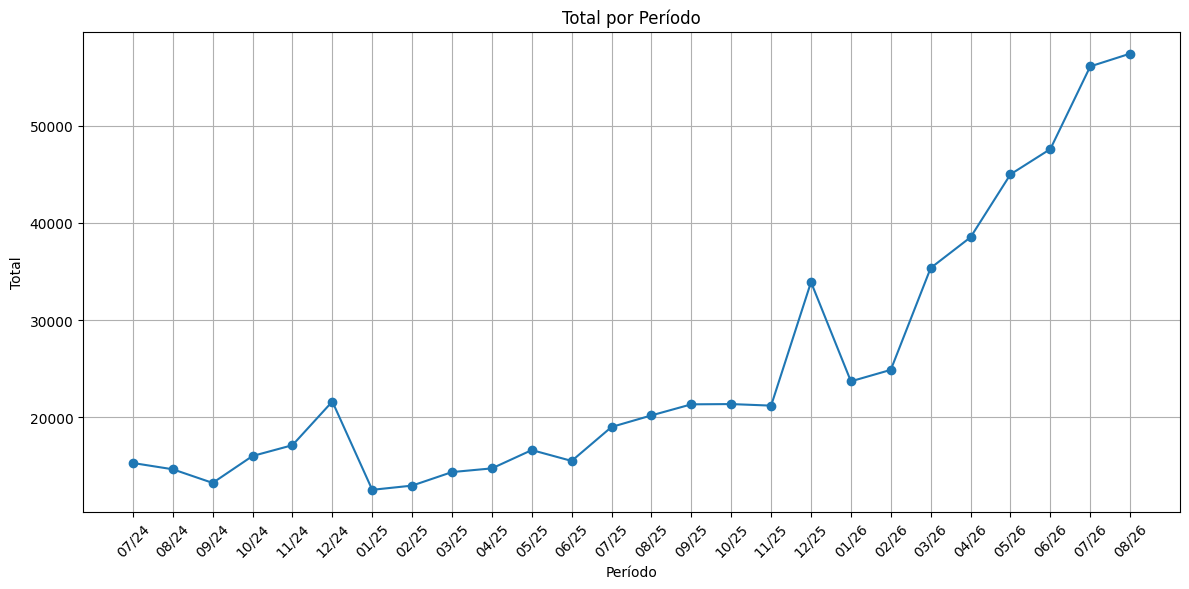

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(df['Período'], df['TOTAL'], marker='o')
plt.xlabel('Período')
plt.ylabel('Total')
plt.title('Total por Período')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

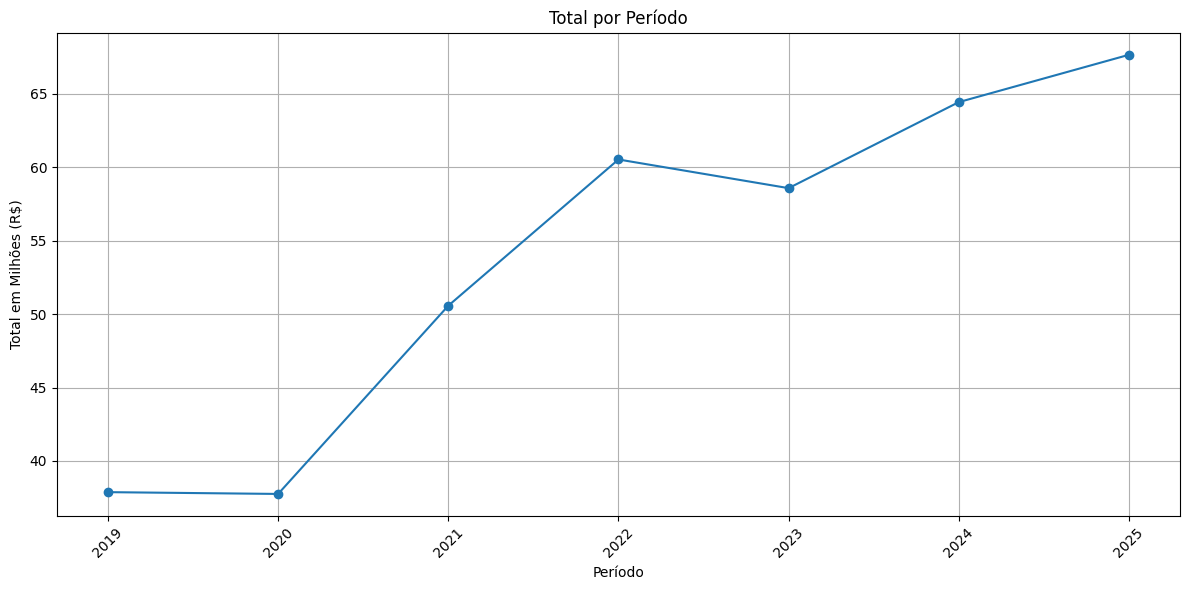

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(dfparts['Ano'], dfparts['Vendas'], marker='o')
plt.xlabel('Período')
plt.ylabel('Total em Milhões (R$)')
plt.title('Total por Período')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
dfparts["Ano"]

,Ano
0,2019
1,2020
2,2021
3,2022
4,2023
5,2024
6,2025


ValueError: not enough values to unpack (expected 2, got 1)

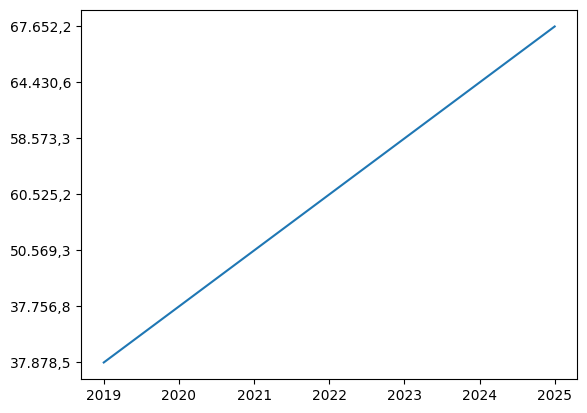

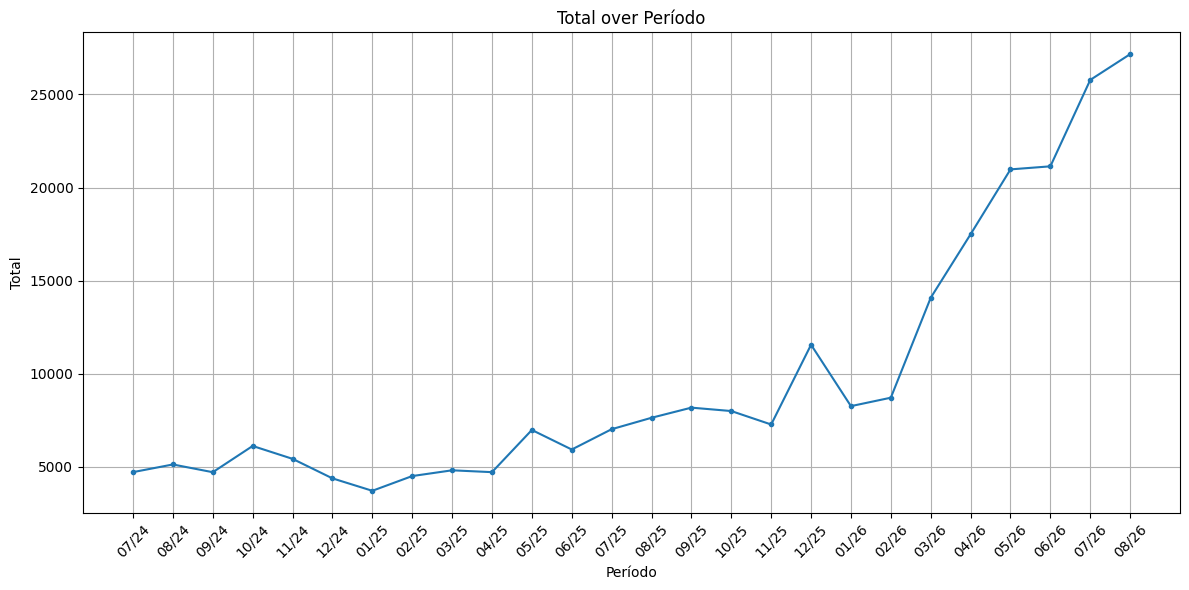

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(df['Período'], df['BEV'], marker='.')
plt.xlabel('Período')
plt.ylabel('Total')
plt.title('Total over Período')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

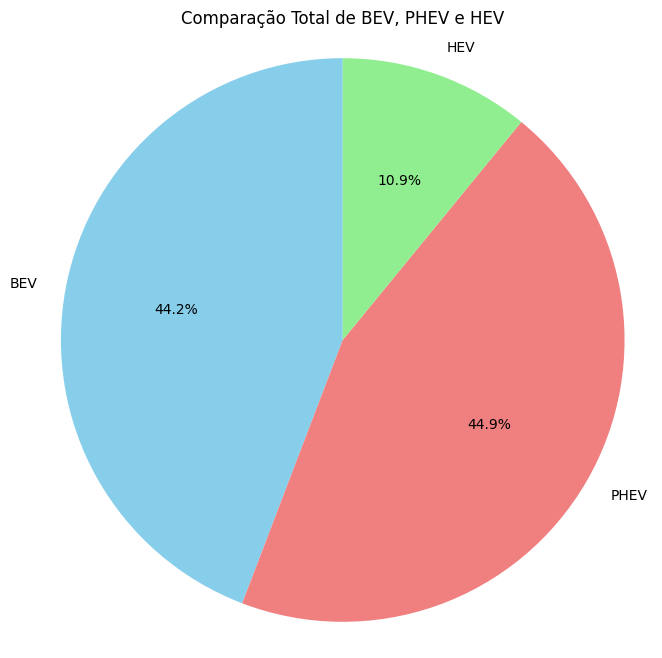

In [ ]:
total_bev = df['BEV'].sum()
total_phev = df['PHEV'].sum()
total_hev = df['HEV'].sum()

data = [total_bev, total_phev, total_hev]
labels = ['BEV', 'PHEV', 'HEV']

plt.figure(figsize=(8, 8))
plt.pie(data, labels=labels, autopct='%1.1f%%', startangle=90, colors=['skyblue', 'lightcoral', 'lightgreen'])
plt.title('Comparação Total de BEV, PHEV e HEV')
plt.axis('equal')
plt.show()